# BÀI 4. XÂY DỰNG MÔ HÌNH MLP CHO DỮ LIỆU ẢNH

## Fashion-MNIST


## 1. Chuẩn bị môi trường và thư viện

Trong Deep Learning, chúng ta thường cần:

- thư viện xử lý số liệu;
- thư viện trực quan hóa;
- framework Deep Learning;
- công cụ đánh giá mô hình.

In [34]:
# Cài các thư viện notebook cần dùng nhưng môi trường hiện chưa có.
import importlib.util
import subprocess
import sys

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "tensorflow": "tensorflow",
    "sklearn": "scikit-learn",
}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])


In [35]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


### Hướng dẫn đọc kết quả

- `TensorFlow version` cho biết phiên bản framework đang sử dụng.
- `GPU available` cho biết Colab có nhận GPU hay không.
- Với Fashion-MNIST và MLP nhỏ, CPU vẫn có thể chạy được; tuy nhiên GPU giúp huấn luyện nhanh hơn.

### Phân tích thực tế

Trong các dự án Deep Learning lớn, môi trường tính toán ảnh hưởng trực tiếp đến thời gian huấn luyện. Vì vậy, kiểm tra GPU là một bước quen thuộc trước khi bắt đầu.

## 2. Thiết lập random seed để tăng khả năng tái lập kết quả

Deep Learning có nhiều yếu tố ngẫu nhiên:
- khởi tạo trọng số;
- thứ tự mini-batch;
- một số phép toán trên GPU.

Đặt seed giúp các lần chạy cho kết quả gần nhau hơn.

In [36]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed =", SEED)

Random seed = 42


### Hướng dẫn đọc kết quả

Nếu notebook được chạy lại với cùng seed, quá trình huấn luyện thường cho kết quả gần tương tự.

### Phân tích thực tế

Không nên hiểu seed là đảm bảo 100% mọi lần chạy giống hệt nhau trên mọi phần cứng. Tuy nhiên, đây là bước quan trọng để thí nghiệm có tính **reproducibility**.

## 3. Tải dữ liệu Fashion-MNIST

Keras cung cấp sẵn Fashion-MNIST nên không cần tải file thủ công.

Dữ liệu gốc đã được chia thành:
- **60,000 ảnh training**
- **10,000 ảnh test**

Sau đó ta sẽ tiếp tục tách một phần training thành validation.

In [37]:
fashion_mnist = tf.keras.datasets.fashion_mnist

(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("X_train_full:", X_train_full.shape)
print("y_train_full:", y_train_full.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Kiểu dữ liệu ảnh:", X_train_full.dtype)
print("Khoảng giá trị pixel:", X_train_full.min(), "->", X_train_full.max())

X_train_full: (60000, 28, 28)
y_train_full: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)
Kiểu dữ liệu ảnh: uint8
Khoảng giá trị pixel: 0 -> 255


### Hướng dẫn đọc kết quả

- `(60000, 28, 28)` nghĩa là có 60,000 ảnh, mỗi ảnh kích thước 28×28.
- Nhãn có dạng vector 1 chiều, mỗi phần tử là một số nguyên từ 0 đến 9.
- Pixel ảnh gốc nằm trong khoảng **0–255**.

### Phân tích thực tế

Ảnh không phải là một bảng feature được thiết kế sẵn như bài hồi quy hay classification trước. Mỗi pixel chính là một giá trị đầu vào. Đây là điểm chuyển quan trọng từ dữ liệu bảng sang dữ liệu ảnh.

## 4. Khám phá nhanh dữ liệu ảnh

Ở bài này chúng ta **không tập trung vào EDA sâu** như với dữ liệu bảng.  
Mục đích của bước này chỉ là:

1. hiểu ảnh trông như thế nào;
2. kiểm tra nhãn;
3. kiểm tra phân bố lớp;
4. xác nhận dữ liệu hợp lý trước khi huấn luyện.

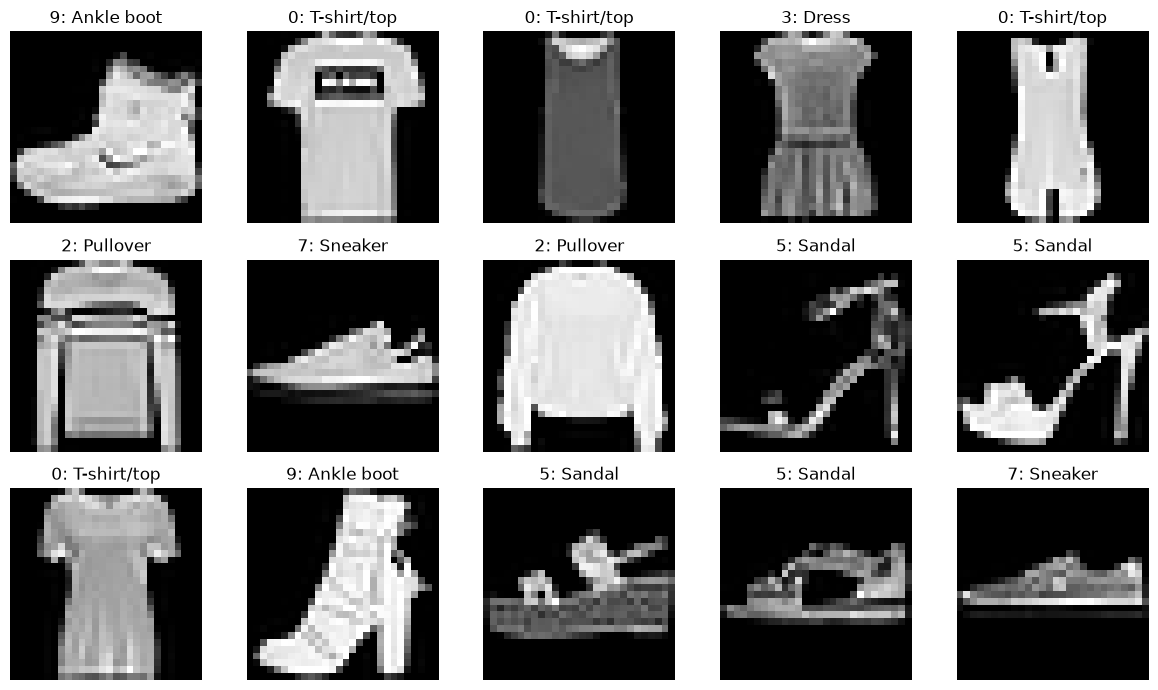

In [38]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_full[i], cmap="gray")
    ax.set_title(f"{y_train_full[i]}: {class_names[y_train_full[i]]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Hướng dẫn đọc kết quả

Mỗi ảnh được hiển thị cùng:
- mã nhãn;
- tên lớp tương ứng.

### Phân tích thực tế

Ảnh Fashion-MNIST khá nhỏ và không chứa màu. Một số lớp có hình dạng gần nhau như:
- `T-shirt/top`;
- `Shirt`;
- `Pullover`;
- `Coat`.

Do đó đây là bài toán khó hơn nhận dạng chữ số MNIST.

In [39]:
unique, counts = np.unique(y_train_full, return_counts=True)

class_distribution = pd.DataFrame({
    "class_id": unique,
    "class_name": [class_names[i] for i in unique],
    "count": counts
})

display(class_distribution)

,class_id,class_name,count
0,0,T-shirt/top,6000
1,1,Trouser,6000
2,2,Pullover,6000
3,3,Dress,6000
4,4,Coat,6000
5,5,Sandal,6000
6,6,Shirt,6000
7,7,Sneaker,6000
8,8,Bag,6000
9,9,Ankle boot,6000


### Hướng dẫn đọc kết quả

Bảng cho biết số mẫu của từng lớp.

### Phân tích thực tế

Fashion-MNIST được xây dựng khá cân bằng, nên ở bài này **không cần sampling để xử lý class imbalance** như bài 3. Điều đó giúp ta tập trung vào quy trình huấn luyện Deep Learning.

## 5. Tách Training / Validation / Test

Trong Deep Learning, ba tập dữ liệu có vai trò khác nhau:

- **Training set**: dùng để cập nhật trọng số mô hình bằng gradient descent.
- **Validation set**: dùng để theo dõi khả năng tổng quát hóa trong quá trình huấn luyện và lựa chọn epoch/hyperparameter.
- **Test set**: chỉ dùng ở cuối để đánh giá mô hình đã hoàn thiện.

> Không nên dùng test set để điều chỉnh mô hình.

In [40]:
VAL_SIZE = 10_000

X_val = X_train_full[-VAL_SIZE:]
y_val = y_train_full[-VAL_SIZE:]

X_train = X_train_full[:-VAL_SIZE]
y_train = y_train_full[:-VAL_SIZE]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (50000, 28, 28) (50000,)
Validation: (10000, 28, 28) (10000,)
Test: (10000, 28, 28) (10000,)


### Hướng dẫn đọc kết quả

Ta thu được:
- 50,000 mẫu training;
- 10,000 mẫu validation;
- 10,000 mẫu test.

### Phân tích thực tế

Validation set đóng vai trò rất quan trọng trong Deep Learning vì một mô hình có thể tiếp tục giảm training loss nhưng bắt đầu tăng validation loss. Đó là dấu hiệu overfitting.

## 6. Chuẩn hóa dữ liệu ảnh

Mỗi pixel ban đầu nằm trong khoảng `[0, 255]`.

Ta chuyển sang `float32` và chia cho 255 để đưa dữ liệu về `[0, 1]`.

Việc chuẩn hóa giúp:
- gradient ổn định hơn;
- tối ưu dễ hơn;
- các layer nhận dữ liệu ở thang đo phù hợp.

In [41]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training min/max:", X_train.min(), X_train.max())
print("Validation min/max:", X_val.min(), X_val.max())
print("Test min/max:", X_test.min(), X_test.max())

Training min/max: 0.0 1.0
Validation min/max: 0.0 1.0
Test min/max: 0.0 1.0


### Hướng dẫn đọc kết quả

Sau chuẩn hóa:
- giá trị nhỏ nhất ≈ 0;
- giá trị lớn nhất ≈ 1.

### Phân tích thực tế

Trong Deep Learning, scale dữ liệu thường ảnh hưởng mạnh đến tốc độ hội tụ. Với ảnh xám, chia cho 255 là cách chuẩn hóa đơn giản và hiệu quả.

## 7. Tạo input pipeline bằng `tf.data`

Deep Learning thường huấn luyện bằng **mini-batch**, không đưa toàn bộ dữ liệu vào mô hình cùng lúc.

`tf.data.Dataset` giúp:
- tạo batch;
- shuffle dữ liệu;
- prefetch dữ liệu;
- xây dựng pipeline có thể mở rộng cho dữ liệu lớn.

In [42]:
BATCH_SIZE = 64

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

for images, labels in train_ds.take(1):
    print("Batch images shape:", images.shape)
    print("Batch labels shape:", labels.shape)

Batch images shape: (64, 28, 28)
Batch labels shape: (64,)


### Hướng dẫn đọc kết quả

Một batch có dạng:

- ảnh: `(batch_size, 28, 28)`
- nhãn: `(batch_size,)`

### Phân tích thực tế

Mini-batch là đơn vị cơ bản của quá trình huấn luyện Deep Learning. Mỗi batch đi qua:
1. forward pass;
2. tính loss;
3. backpropagation;
4. cập nhật trọng số.

Sau khi đi hết mọi batch, ta hoàn thành **1 epoch**.

## 8. Xây dựng mô hình MLP

Ảnh có dạng ma trận `28 × 28`.  
MLP yêu cầu vector đầu vào, nên trước hết cần **Flatten** ảnh:

\[
28 \times 28 = 784
\]

Sau đó dữ liệu đi qua các Dense layer:

\[
784 \rightarrow 256 \rightarrow 128 \rightarrow 10
\]

Layer cuối có 10 neuron, tương ứng 10 lớp.

In [43]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Hướng dẫn đọc kết quả

`model.summary()` cho biết:
- tên từng layer;
- kích thước output;
- số parameter cần học.

Dense layer có số tham số:

`input_size × output_size + bias`

### Phân tích thực tế

Số parameter của MLP có thể khá lớn dù ảnh chỉ 28×28. Nguyên nhân là mỗi neuron Dense kết nối với toàn bộ đầu vào. Đây cũng là một lý do CNN thường hiệu quả hơn cho dữ liệu ảnh.

## 9. Compile mô hình

Trước khi train, cần xác định ba thành phần:

1. **Optimizer** – cách cập nhật trọng số.
2. **Loss function** – hàm mục tiêu cần tối thiểu hóa.
3. **Metric** – chỉ số theo dõi hiệu năng.

Ở đây sử dụng:

- Optimizer: `Adam`
- Loss: `SparseCategoricalCrossentropy`
- Metric: `accuracy`

Vì nhãn được lưu dưới dạng số nguyên `0...9`, ta dùng **sparse categorical cross-entropy**.

In [44]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


### Hướng dẫn đọc kết quả

Nếu cell chạy không lỗi, mô hình đã sẵn sàng để huấn luyện.

### Phân tích thực tế

`compile()` không huấn luyện mô hình. Nó chỉ thiết lập quy tắc huấn luyện. Việc cập nhật trọng số chỉ xảy ra khi gọi `fit()`.

## 10. Callback trong Deep Learning

Huấn luyện mạng nơ-ron có thể kéo dài nhiều epoch. Callback giúp kiểm soát quá trình này.

Ta sử dụng:

### EarlyStopping
Dừng huấn luyện khi validation loss không còn cải thiện.

### ModelCheckpoint
Lưu lại mô hình có validation loss tốt nhất.

Đây là workflow phổ biến trong thực tế để tránh giữ mô hình ở epoch cuối nếu epoch đó đã overfit.

In [45]:
checkpoint_path = "best_mlp_fashion.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

print("Callbacks ready.")

Callbacks ready.


## 11. Huấn luyện mô hình

Trong mỗi epoch:

1. mô hình chạy qua toàn bộ training set;
2. optimizer cập nhật trọng số theo từng mini-batch;
3. cuối epoch, mô hình được đánh giá trên validation set.

Ta theo dõi đồng thời:
- `loss`;
- `accuracy`;
- `val_loss`;
- `val_accuracy`.

In [46]:
EPOCHS = 40

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40


c:\Users\dauvv\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8202 - loss: 0.5029 - val_accuracy: 0.8474 - val_loss: 0.4315
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8637 - loss: 0.3716 - val_accuracy: 0.8697 - val_loss: 0.3632
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8785 - loss: 0.3298 - val_accuracy: 0.8749 - val_loss: 0.3431
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8864 - loss: 0.3056 - val_accuracy: 0.8730 - val_loss: 0.3463
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8939 - loss: 0.2856 - val_accuracy: 0.8825 - val_loss: 0.3270
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9002 - loss: 0.2720 - val_accuracy: 0.8855 - val_loss: 0.3214
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9023 - loss: 0.2616 - val_accuracy: 0.8892 - val_loss: 0.3109
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9081 - loss: 0.2457 - val_accuracy: 0.8861 - val_

### Hướng dẫn đọc kết quả

Mỗi dòng epoch thường có:

- `loss`: training loss;
- `accuracy`: training accuracy;
- `val_loss`: validation loss;
- `val_accuracy`: validation accuracy.

### Phân tích thực tế

Một quá trình học tốt thường có:
- training loss giảm;
- validation loss cũng giảm trong giai đoạn đầu;
- accuracy tăng dần.

Nếu training loss tiếp tục giảm nhưng validation loss tăng, mô hình đang **overfitting**.

## 12. Trực quan hóa learning curves

Learning curve là công cụ quan trọng để đọc quá trình huấn luyện Deep Learning.

Ta sẽ vẽ:
- Loss theo epoch;
- Accuracy theo epoch.

In [47]:
history_df = pd.DataFrame(history.history)
display(history_df.tail())

,accuracy,loss,val_accuracy,val_loss
5,0.90024,0.271983,0.8855,0.321433
6,0.90230,0.261602,0.8892,0.310912
7,0.90808,0.245741,0.8861,0.316525
8,0.91166,0.235302,0.8884,0.315142
9,0.91486,0.228825,0.8908,0.313905


### Hướng dẫn đọc kết quả

Mỗi dòng tương ứng một epoch.  
Bảng này là dữ liệu nguồn để phân tích quá trình học.

### Phân tích thực tế

Không nên chỉ nhìn accuracy cuối cùng. Lịch sử training giúp ta biết:
- mô hình học nhanh hay chậm;
- bắt đầu overfit ở epoch nào;
- callback có dừng hợp lý không.

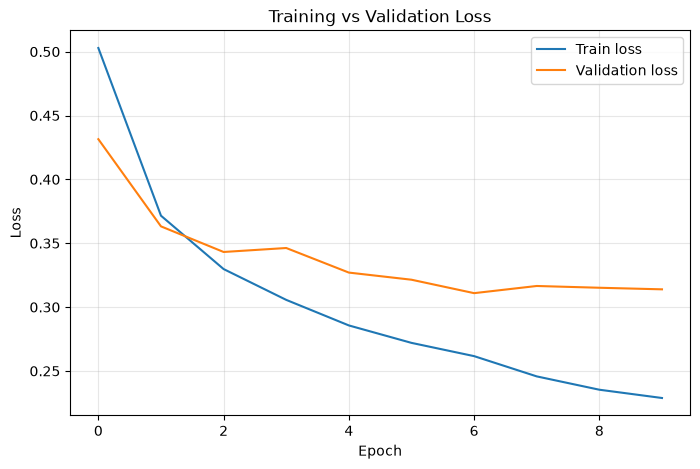

In [48]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Hướng dẫn đọc kết quả

- Đường train loss cho biết mức lỗi trên training set.
- Đường validation loss cho biết khả năng tổng quát hóa trên dữ liệu chưa dùng để cập nhật trọng số.

### Phân tích thực tế

- Hai đường cùng giảm: mô hình đang học tốt.
- Train loss giảm nhưng val loss tăng: overfitting.
- Cả hai đều cao và gần nhau: có thể underfitting.

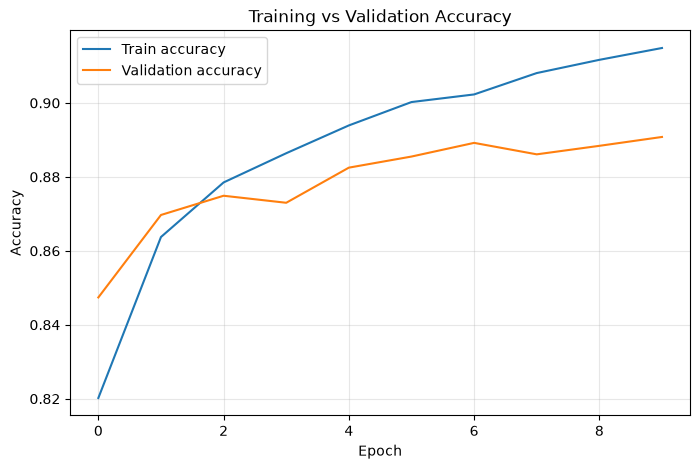

In [49]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Hướng dẫn đọc kết quả

So sánh khoảng cách giữa training accuracy và validation accuracy.

### Phân tích thực tế

Khoảng cách nhỏ thường cho thấy mô hình tổng quát hóa tương đối tốt. Nếu training accuracy cao hơn validation accuracy quá nhiều, mô hình có thể đang ghi nhớ training set.

## 13. Đánh giá cuối cùng trên Test Set

Sau khi quá trình train và lựa chọn mô hình hoàn tất, ta mới đánh giá trên test set.

Test set đóng vai trò như dữ liệu hoàn toàn mới.

In [50]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")

Test loss     : 0.3358
Test accuracy : 0.8816


### Hướng dẫn đọc kết quả

`Test accuracy` là tỷ lệ dự đoán đúng trên dữ liệu test.

### Phân tích thực tế

Nếu validation accuracy và test accuracy gần nhau, kết quả validation có khả năng phản ánh tốt khả năng tổng quát hóa. Nếu test accuracy giảm mạnh, quy trình tuning có thể đã phụ thuộc quá nhiều vào validation set.

## 14. Dự đoán xác suất và nhãn lớp

Layer cuối dùng Softmax nên mô hình trả về một vector xác suất cho 10 lớp.

Ví dụ:

`[0.01, 0.00, 0.02, ..., 0.90]`

Lớp có xác suất lớn nhất được chọn làm dự đoán.

In [51]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Probability shape:", y_prob.shape)
print("5 nhãn thật đầu tiên:", y_test[:5])
print("5 nhãn dự đoán đầu tiên:", y_pred[:5])

Probability shape: (10000, 10)
5 nhãn thật đầu tiên: [9 2 1 1 6]
5 nhãn dự đoán đầu tiên: [9 2 1 1 6]


### Hướng dẫn đọc kết quả

- `y_prob.shape = (10000, 10)` nghĩa là mỗi ảnh có 10 xác suất.
- `argmax` lấy vị trí có xác suất lớn nhất làm nhãn dự đoán.

### Phân tích thực tế

Trong nhiều ứng dụng, xác suất dự đoán cũng quan trọng như nhãn cuối cùng vì nó cho biết độ tự tin tương đối của mô hình.

## 15. Confusion Matrix

Accuracy cho biết hiệu quả tổng thể, nhưng không cho biết mô hình nhầm lớp nào với lớp nào.

Confusion matrix giúp phân tích lỗi chi tiết hơn.

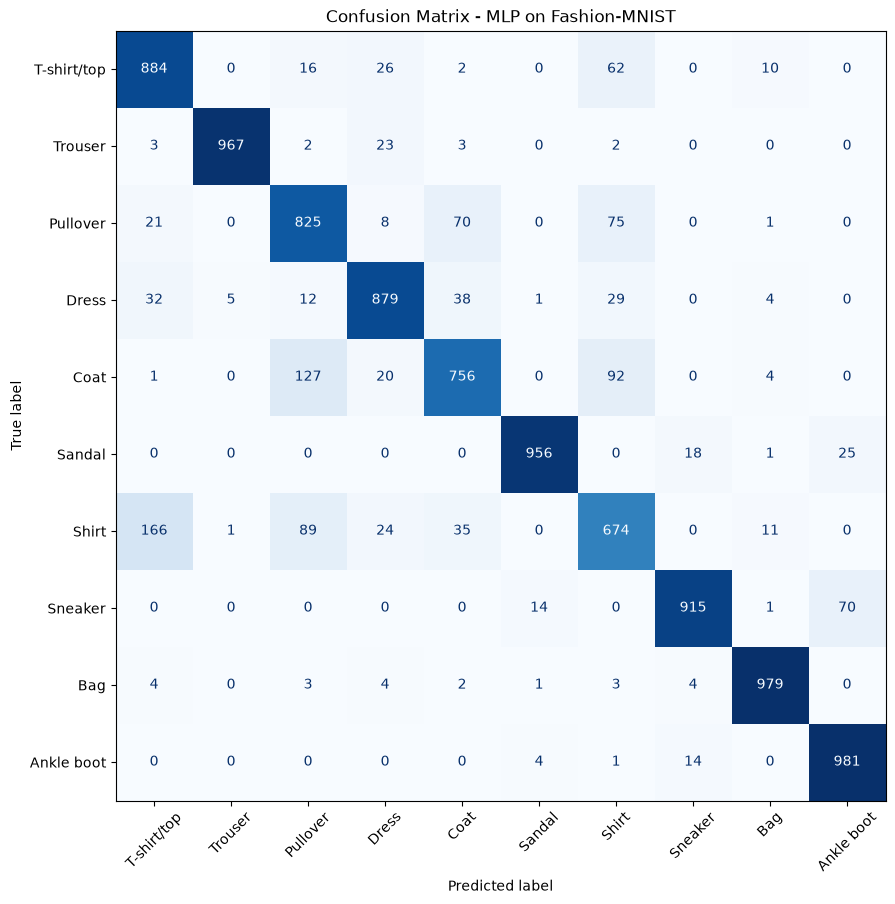

In [52]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - MLP on Fashion-MNIST")
plt.show()

### Hướng dẫn đọc kết quả

- Giá trị trên đường chéo: số mẫu dự đoán đúng.
- Giá trị ngoài đường chéo: các trường hợp bị nhầm lớp.

### Phân tích thực tế

Với Fashion-MNIST, mô hình thường dễ nhầm các nhóm có hình dạng tương tự nhau như:
- Shirt và T-shirt/top;
- Shirt và Pullover;
- Coat và Pullover.

Confusion matrix cho phép nhìn rõ loại lỗi này hơn accuracy.

## 16. Classification Report

Ta xem thêm:
- precision;
- recall;
- F1-score;
- support.

Mục tiêu ở đây không phải học lại toàn bộ metric của bài 3, mà là biết cách kiểm tra hiệu năng theo từng lớp.

In [53]:
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

 T-shirt/top     0.7957    0.8840    0.8375      1000
     Trouser     0.9938    0.9670    0.9802      1000
    Pullover     0.7682    0.8250    0.7956      1000
       Dress     0.8933    0.8790    0.8861      1000
        Coat     0.8344    0.7560    0.7933      1000
      Sandal     0.9795    0.9560    0.9676      1000
       Shirt     0.7186    0.6740    0.6956      1000
     Sneaker     0.9621    0.9150    0.9380      1000
         Bag     0.9683    0.9790    0.9736      1000
  Ankle boot     0.9117    0.9810    0.9451      1000

    accuracy                         0.8816     10000
   macro avg     0.8826    0.8816    0.8813     10000
weighted avg     0.8826    0.8816    0.8813     10000



### Hướng dẫn đọc kết quả

- `precision`: trong các mẫu mô hình dự đoán là một lớp, bao nhiêu mẫu đúng.
- `recall`: trong các mẫu thực sự thuộc lớp đó, mô hình tìm đúng bao nhiêu.
- `f1-score`: cân bằng precision và recall.

### Phân tích thực tế

Dù dữ liệu cân bằng, một số lớp vẫn có F1 thấp hơn vì bản thân hình ảnh giữa các lớp đó khó phân biệt.

## 17. Trực quan hóa các dự đoán

Ta hiển thị một số ảnh cùng:
- nhãn thật;
- nhãn dự đoán;
- xác suất cao nhất.

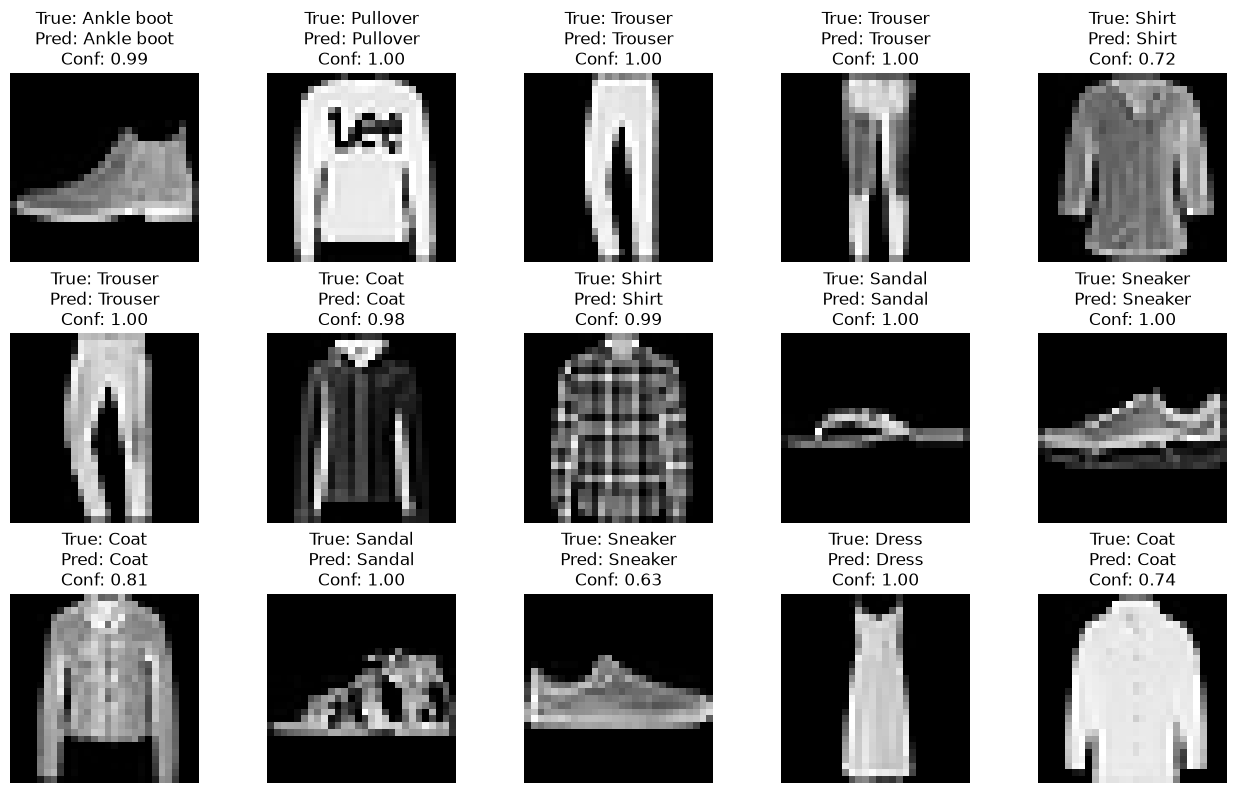

In [54]:
indices = np.arange(15)

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for idx, ax in zip(indices, axes.ravel()):
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    confidence = y_prob[idx][pred_label]

    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Conf: {confidence:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Hướng dẫn đọc kết quả

Mỗi ảnh cho biết:
- lớp thật;
- lớp mô hình chọn;
- confidence của lớp được chọn.

### Phân tích thực tế

Các mẫu dự đoán sai nhưng confidence cao là những ví dụ rất quan trọng để phân tích lỗi mô hình. Trong các bài toán thực tế, đây thường là nhóm cần được điều tra sâu hơn.

## 18. Phân tích các mẫu dự đoán sai

Thay vì chỉ xem accuracy, ta chủ động tìm các ảnh mà mô hình dự đoán sai.

Số mẫu dự đoán sai: 1184


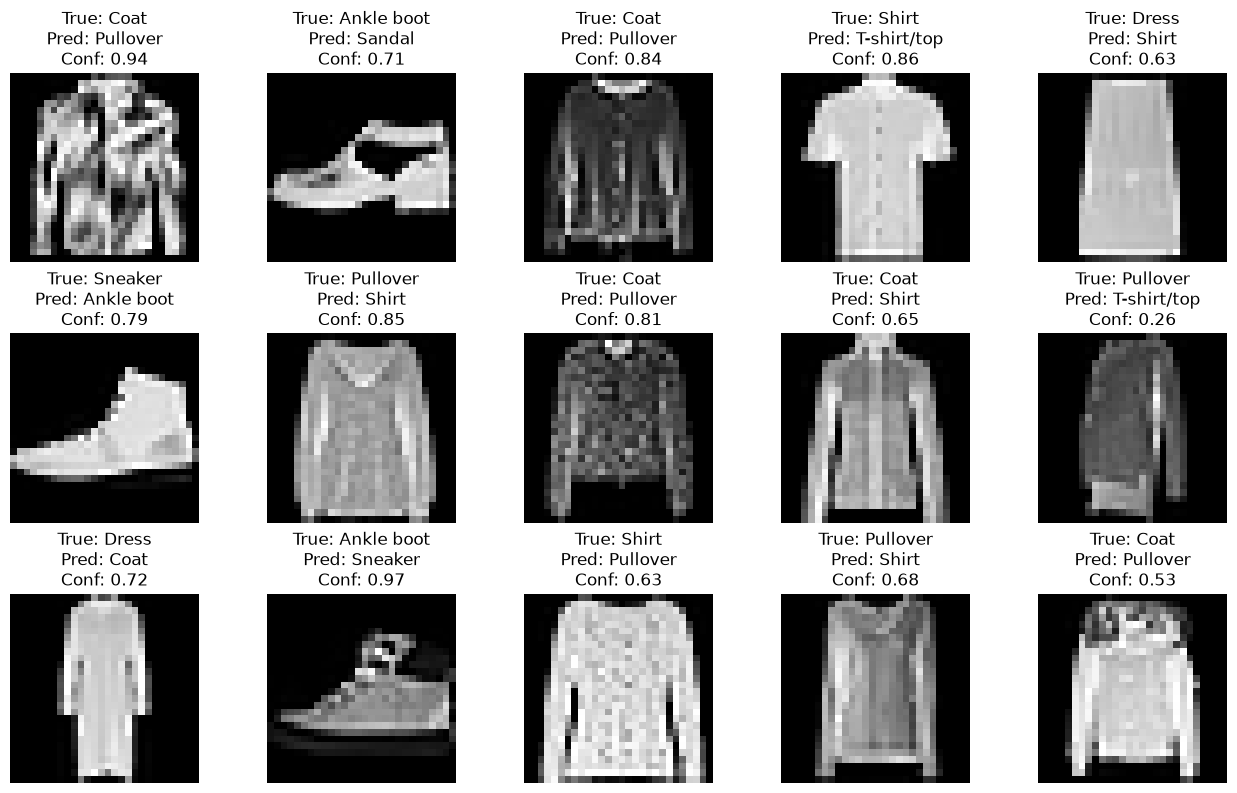

In [55]:
wrong_indices = np.where(y_pred != y_test)[0]

print("Số mẫu dự đoán sai:", len(wrong_indices))

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for idx, ax in zip(wrong_indices[:15], axes.ravel()):
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    confidence = y_prob[idx][pred_label]

    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Conf: {confidence:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Hướng dẫn đọc kết quả

Chỉ các mẫu mô hình dự đoán sai được hiển thị.

### Phân tích thực tế

Error analysis là bước quan trọng của workflow Deep Learning. Từ lỗi thực tế, ta mới quyết định có cần:
- mô hình sâu hơn;
- regularization;
- thêm dữ liệu;
- data augmentation;
- đổi kiến trúc sang CNN.

## 19. Inference trên một ảnh riêng lẻ

Trong thực tế, mô hình thường nhận một hoặc một vài mẫu mới chứ không phải cả test set.

Ta chọn một ảnh và mô phỏng quy trình inference.

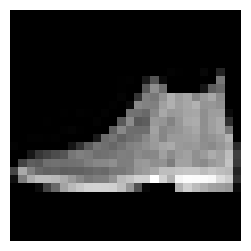

True label : Ankle boot
Prediction : Ankle boot
Confidence : 0.9902413487434387


In [56]:
sample_image = X_test[0]
sample_true_label = y_test[0]

sample_prob = model.predict(sample_image[None, ...], verbose=0)[0]
sample_pred = np.argmax(sample_prob)

plt.figure(figsize=(3, 3))
plt.imshow(sample_image, cmap="gray")
plt.axis("off")
plt.show()

print("True label :", class_names[sample_true_label])
print("Prediction :", class_names[sample_pred])
print("Confidence :", float(sample_prob[sample_pred]))

### Hướng dẫn đọc kết quả

`sample_image[None, ...]` thêm chiều batch:

- trước: `(28, 28)`
- sau: `(1, 28, 28)`

### Phân tích thực tế

Framework Deep Learning thường yêu cầu input có batch dimension ngay cả khi chỉ dự đoán một ảnh.

## 20. Lưu và khôi phục mô hình

Sau khi huấn luyện xong, mô hình cần được lưu để:
- triển khai;
- tiếp tục huấn luyện;
- tái sử dụng sau này.

Keras cho phép lưu toàn bộ kiến trúc và trọng số vào file `.keras`.

In [57]:
final_model_path = "fashion_mnist_mlp_final.keras"

model.save(final_model_path)

loaded_model = tf.keras.models.load_model(final_model_path)

loaded_loss, loaded_acc = loaded_model.evaluate(test_ds, verbose=0)

print("Loaded model test accuracy:", round(float(loaded_acc), 4))

Loaded model test accuracy: 0.8816


### Hướng dẫn đọc kết quả

Nếu accuracy sau khi load gần như giống mô hình trước khi lưu, quá trình lưu/khôi phục đã thành công.

### Phân tích thực tế

Đây là bước nối từ training sang deployment. Trong dự án thật, model artifact cần được quản lý cùng:
- phiên bản dữ liệu;
- hyperparameter;
- code;
- metric.

# 21. Tổng kết workflow Deep Learning

Một workflow Deep Learning điển hình:

**Bước 1. Chuẩn bị dữ liệu**  
↓  
**Bước 2. Train / Validation / Test split**  
↓  
**Bước 3. Tiền xử lý và tạo batch**  
↓  
**Bước 4. Xây dựng kiến trúc mạng**  
↓  
**Bước 5. Compile: optimizer + loss + metric**  
↓  
**Bước 6. Train bằng mini-batch**  
↓  
**Bước 7. Theo dõi validation và callback**  
↓  
**Bước 8. Phân tích learning curves**  
↓  
**Bước 9. Đánh giá trên test set**  
↓  
**Bước 10. Error analysis**  
↓  
**Bước 11. Inference và lưu mô hình**

---

## So sánh nhanh với workflow Machine Learning cổ điển

| Machine Learning cổ điển | Deep Learning |
|---|---|
| Feature engineering thường rất quan trọng | Mô hình học representation từ dữ liệu |
| `fit(X_train, y_train)` thường là một bước tương đối gọn | Training gồm nhiều epoch và mini-batch |
| Ít cần quan sát quá trình tối ưu | Cần theo dõi loss/metric theo epoch |
| Model selection dựa nhiều vào CV | Validation set và learning curve rất quan trọng |
| Model thường nhỏ | Số parameter có thể rất lớn |
| Training nhanh | Training có thể tốn GPU và thời gian |

---

## Câu hỏi thảo luận

1. Vì sao MLP cần `Flatten` ảnh trước Dense layer?
2. Validation set khác test set ở điểm nào?
3. Một epoch là gì? Một batch là gì?
4. Khi nào training loss giảm nhưng validation loss tăng?
5. EarlyStopping giúp giải quyết vấn đề gì?
6. Vì sao không nên dùng test set để chọn hyperparameter?
7. Tại sao MLP chưa phải kiến trúc tối ưu cho ảnh?
8. Nếu tăng số neuron/layer, điều gì có thể xảy ra?
9. Nếu learning rate quá lớn, learning curve có thể có đặc điểm gì?
10. Bước tiếp theo để cải thiện mô hình cho ảnh là kiến trúc nào?

# 22. Bài tập mở rộng — lời giải

Mỗi bài có tiêu đề và ô chạy riêng. Hãy chạy lần lượt từ trên xuống dưới để tạo bảng và biểu đồ kết quả.


### Hàm dùng chung cho các thí nghiệm

Hàm dưới đây giữ cố định dữ liệu và quy trình huấn luyện để so sánh từng yếu tố. Mỗi lần chạy lưu train/validation accuracy, test accuracy, số tham số, epoch tốt nhất và thời gian.


In [58]:
import time

EXPERIMENT_EPOCHS = 20
EXPERIMENT_PATIENCE = 3
experiment_histories = {}
experiment_results = []


def build_experiment_model(hidden_units, learning_rate=1e-3, dropout_rate=0.0, l2_strength=0.0):
    regularizer = tf.keras.regularizers.l2(l2_strength) if l2_strength > 0 else None
    layers = [tf.keras.layers.Input(shape=(28, 28)), tf.keras.layers.Flatten()]
    for units in hidden_units:
        layers.append(tf.keras.layers.Dense(units, activation="relu", kernel_regularizer=regularizer))
        if dropout_rate > 0:
            layers.append(tf.keras.layers.Dropout(dropout_rate))
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    model_i = tf.keras.Sequential(layers)
    model_i.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model_i


def run_experiment(name, hidden_units, learning_rate=1e-3, batch_size=128,
                   dropout_rate=0.0, l2_strength=0.0):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model_i = build_experiment_model(hidden_units, learning_rate, dropout_rate, l2_strength)
    train_i = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(
        len(X_train), seed=SEED, reshuffle_each_iteration=True
    ).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    val_i = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    test_i = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    started = time.perf_counter()
    hist_i = model_i.fit(
        train_i, validation_data=val_i, epochs=EXPERIMENT_EPOCHS, verbose=0,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=EXPERIMENT_PATIENCE, restore_best_weights=True
        )]
    )
    elapsed = time.perf_counter() - started
    best_idx = int(np.argmin(hist_i.history["val_loss"]))
    test_loss_i, test_acc_i = model_i.evaluate(test_i, verbose=0)
    experiment_histories[name] = hist_i.history
    result = {
        "experiment": name,
        "hidden_layers": len(hidden_units),
        "hidden_units": str(hidden_units),
        "learning_rate": learning_rate,
        "batch_size": batch_size,
        "dropout": dropout_rate,
        "l2": l2_strength,
        "parameters": model_i.count_params(),
        "best_epoch": best_idx + 1,
        "train_accuracy": hist_i.history["accuracy"][best_idx],
        "val_accuracy": hist_i.history["val_accuracy"][best_idx],
        "test_accuracy": test_acc_i,
        "test_loss": test_loss_i,
        "best_val_loss": hist_i.history["val_loss"][best_idx],
        "seconds": elapsed
    }
    experiment_results.append(result)
    return result


def show_experiment_table(names):
    result_df = pd.DataFrame(experiment_results)
    display(result_df[result_df["experiment"].isin(names)].reset_index(drop=True))


## Bài 1. Thay đổi kiến trúc

So sánh MLP có 1, 2 và 3 hidden layers. Bảng và biểu đồ thể hiện số parameter, thời gian train, validation accuracy và test accuracy.


c:\Users\dauvv\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


,experiment,parameters,seconds,best_epoch,val_accuracy,test_accuracy
0,Kiến trúc 1 tầng,203530,13.367103,7,0.8839,0.8779
1,Kiến trúc 2 tầng,235146,22.168503,9,0.8880,0.8838
2,Kiến trúc 3 tầng,242762,28.688811,12,0.8888,0.8839


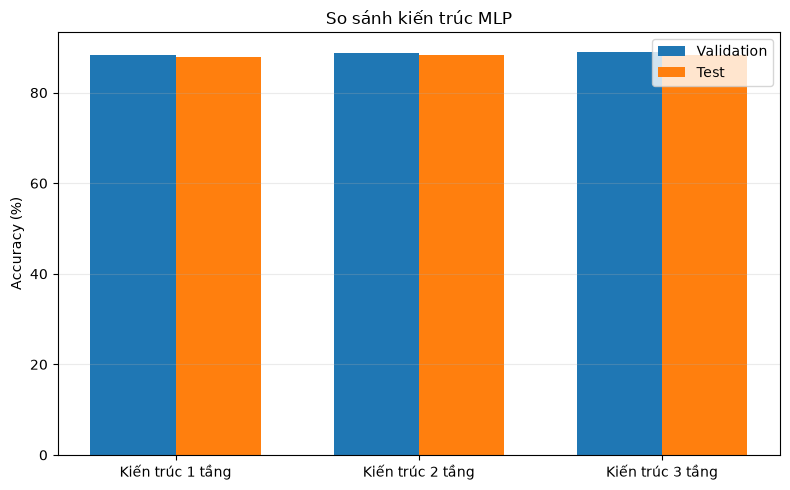

In [59]:
architecture_names = ["Kiến trúc 1 tầng", "Kiến trúc 2 tầng", "Kiến trúc 3 tầng"]
architecture_units = [[256], [256, 128], [256, 128, 64]]
for name, units in zip(architecture_names, architecture_units):
    run_experiment(name, units)

architecture_df = pd.DataFrame(experiment_results)
architecture_df = architecture_df[architecture_df["experiment"].isin(architecture_names)].copy()
display(architecture_df[["experiment", "parameters", "seconds", "best_epoch", "val_accuracy", "test_accuracy"]])

x = np.arange(len(architecture_df))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, architecture_df["val_accuracy"] * 100, width, label="Validation")
ax.bar(x + width / 2, architecture_df["test_accuracy"] * 100, width, label="Test")
ax.set_xticks(x)
ax.set_xticklabels(architecture_df["experiment"])
ax.set_ylabel("Accuracy (%)")
ax.set_title("So sánh kiến trúc MLP")
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()


## Bài 2. Thử learning rate

Huấn luyện với learning rate `1e-2`, `1e-3`, `1e-4`; xem loss và accuracy theo epoch, đồng thời so sánh test accuracy.


c:\Users\dauvv\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


,experiment,hidden_layers,hidden_units,learning_rate,batch_size,dropout,l2,parameters,best_epoch,train_accuracy,val_accuracy,test_accuracy,test_loss,best_val_loss,seconds
0,Learning rate 0.01,2,"[256, 128]",0.0100,128,0.0,0.0,235146,6,0.88032,0.8783,0.8710,0.368004,0.349533,18.887647
1,Learning rate 0.001,2,"[256, 128]",0.0010,128,0.0,0.0,235146,9,0.91036,0.8880,0.8838,0.329110,0.309768,24.594732
2,Learning rate 0.0001,2,"[256, 128]",0.0001,128,0.0,0.0,235146,16,0.89876,0.8822,0.8770,0.350800,0.326392,37.084549


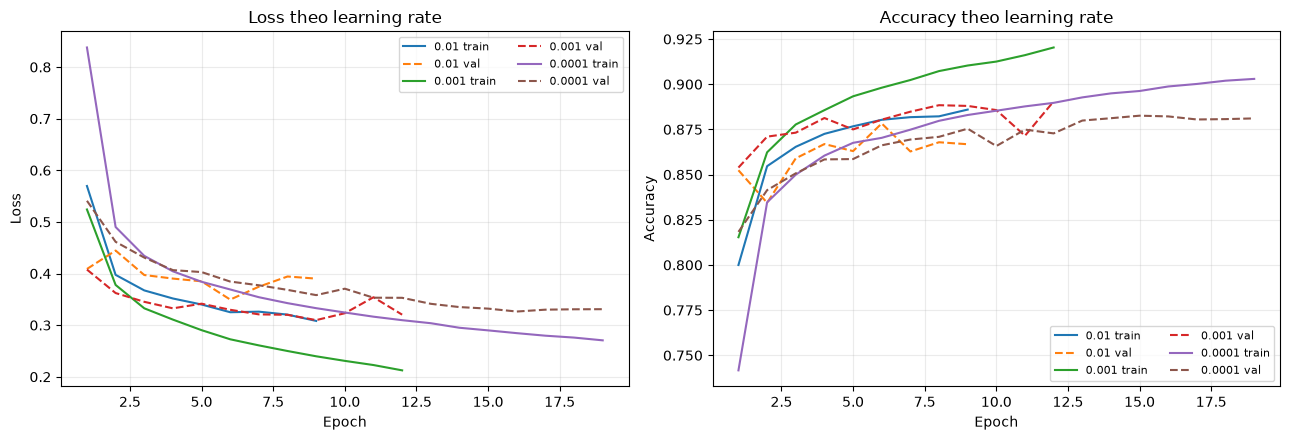

In [60]:
lr_names = []
for lr in [1e-2, 1e-3, 1e-4]:
    name = f"Learning rate {lr:g}"
    lr_names.append(name)
    run_experiment(name, [256, 128], learning_rate=lr)
show_experiment_table(lr_names)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for lr, name in zip([1e-2, 1e-3, 1e-4], lr_names):
    curve = experiment_histories[name]
    epochs = np.arange(1, len(curve["loss"]) + 1)
    axes[0].plot(epochs, curve["loss"], label=f"{lr:g} train")
    axes[0].plot(epochs, curve["val_loss"], linestyle="--", label=f"{lr:g} val")
    axes[1].plot(epochs, curve["accuracy"], label=f"{lr:g} train")
    axes[1].plot(epochs, curve["val_accuracy"], linestyle="--", label=f"{lr:g} val")
axes[0].set_title("Loss theo learning rate")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].set_title("Accuracy theo learning rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()


## Bài 3. Thử batch size

So sánh batch size 32, 128 và 512 về thời gian train, validation accuracy và test accuracy.


c:\Users\dauvv\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


,experiment,seconds,val_accuracy,test_accuracy,best_epoch
6,Batch size 32,69.727780,0.8875,0.8859,9
7,Batch size 128,20.277831,0.8880,0.8838,9
8,Batch size 512,12.119179,0.8907,0.8876,17


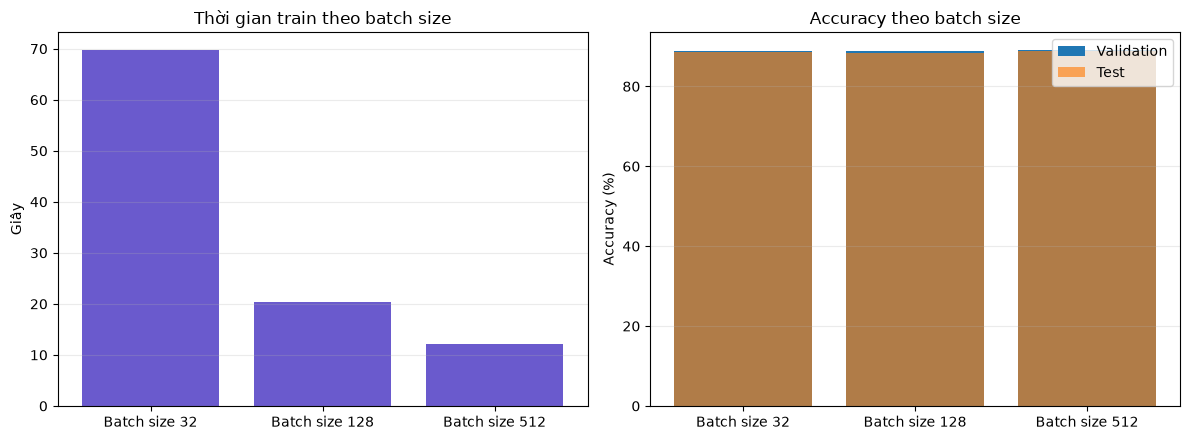

In [61]:
batch_names = []
for batch in [32, 128, 512]:
    name = f"Batch size {batch}"
    batch_names.append(name)
    run_experiment(name, [256, 128], batch_size=batch)
batch_df = pd.DataFrame(experiment_results)
batch_df = batch_df[batch_df["experiment"].isin(batch_names)].copy()
display(batch_df[["experiment", "seconds", "val_accuracy", "test_accuracy", "best_epoch"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(batch_df["experiment"], batch_df["seconds"], color="slateblue")
axes[0].set_title("Thời gian train theo batch size")
axes[0].set_ylabel("Giây")
axes[1].bar(batch_df["experiment"], batch_df["val_accuracy"] * 100, label="Validation")
axes[1].bar(batch_df["experiment"], batch_df["test_accuracy"] * 100, alpha=0.65, label="Test")
axes[1].set_title("Accuracy theo batch size")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## Bài 4. Thêm Dropout

Thêm `Dropout(0.3)` giữa các Dense layer và so sánh khoảng cách train/validation accuracy với mô hình 2 tầng cơ sở.


c:\Users\dauvv\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


,experiment,train_accuracy,val_accuracy,train_val_gap,test_accuracy
1,Kiến trúc 2 tầng,0.91036,0.8880,0.02236,0.8838
9,Dropout 0.3,0.89990,0.8928,0.00710,0.8882


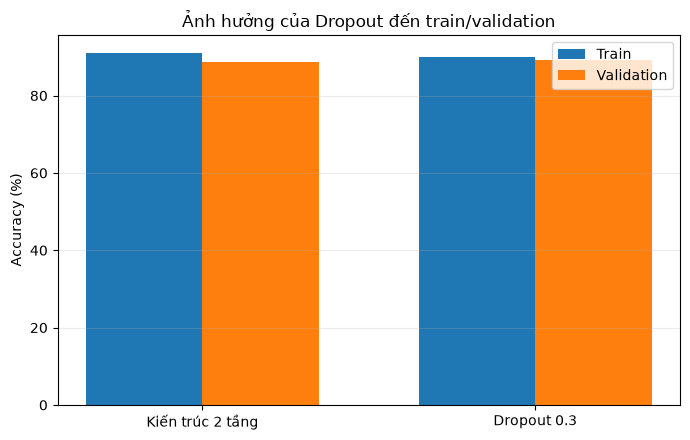

In [62]:
run_experiment("Dropout 0.3", [256, 128], dropout_rate=0.3)
reg_names = ["Kiến trúc 2 tầng", "Dropout 0.3"]
reg_df = pd.DataFrame(experiment_results)
reg_df = reg_df[reg_df["experiment"].isin(reg_names)].copy()
reg_df["train_val_gap"] = reg_df["train_accuracy"] - reg_df["val_accuracy"]
display(reg_df[["experiment", "train_accuracy", "val_accuracy", "train_val_gap", "test_accuracy"]])

x = np.arange(len(reg_df))
width = 0.35
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, reg_df["train_accuracy"] * 100, width, label="Train")
ax.bar(x + width / 2, reg_df["val_accuracy"] * 100, width, label="Validation")
ax.set_xticks(x)
ax.set_xticklabels(reg_df["experiment"])
ax.set_ylabel("Accuracy (%)")
ax.set_title("Ảnh hưởng của Dropout đến train/validation")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## Bài 5. Thêm L2 regularization

Dùng `kernel_regularizer=tf.keras.regularizers.l2(1e-4)` trên các Dense layer; so sánh với mô hình cơ sở.


c:\Users\dauvv\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


,experiment,train_accuracy,val_accuracy,train_val_gap,test_accuracy
1,Kiến trúc 2 tầng,0.91036,0.8880,0.02236,0.8838
10,L2 regularization,0.90044,0.8837,0.01674,0.8773


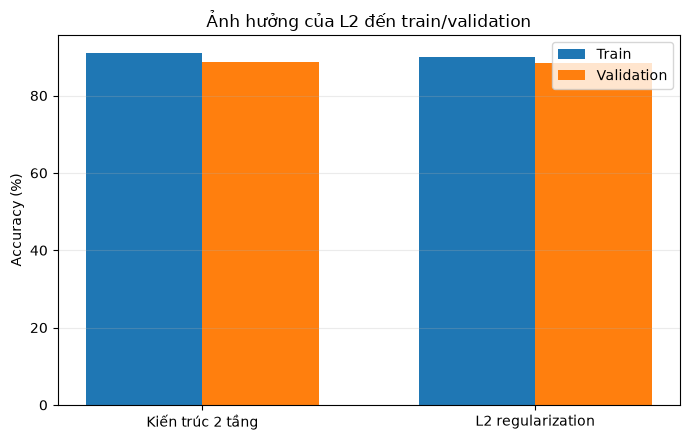

In [63]:
run_experiment("L2 regularization", [256, 128], l2_strength=1e-4)
reg_names = ["Kiến trúc 2 tầng", "L2 regularization"]
reg_df = pd.DataFrame(experiment_results)
reg_df = reg_df[reg_df["experiment"].isin(reg_names)].copy()
reg_df["train_val_gap"] = reg_df["train_accuracy"] - reg_df["val_accuracy"]
display(reg_df[["experiment", "train_accuracy", "val_accuracy", "train_val_gap", "test_accuracy"]])

x = np.arange(len(reg_df))
width = 0.35
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, reg_df["train_accuracy"] * 100, width, label="Train")
ax.bar(x + width / 2, reg_df["val_accuracy"] * 100, width, label="Validation")
ax.set_xticks(x)
ax.set_xticklabels(reg_df["experiment"])
ax.set_ylabel("Accuracy (%)")
ax.set_title("Ảnh hưởng của L2 đến train/validation")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## Bài 6. Phân tích lỗi

Hiển thị 20 dự đoán sai có confidence cao nhất, xếp hạng các cặp lớp thường bị nhầm và nhận xét vì sao ảnh đó khó phân loại.


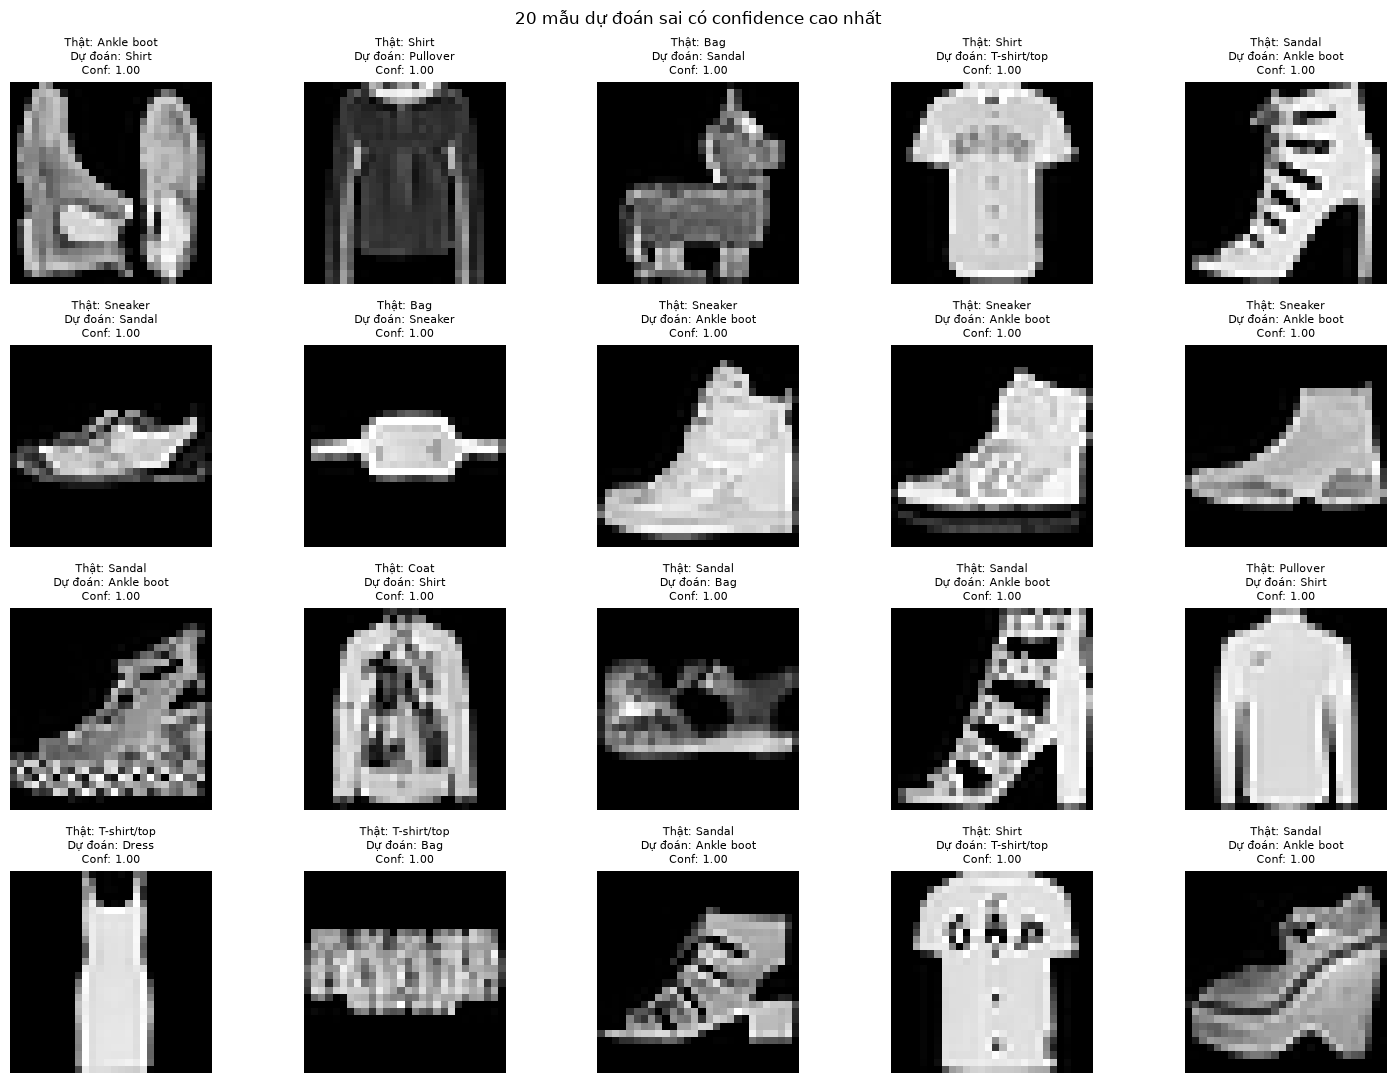

,index,nhãn thật,dự đoán,confidence
0,5512,Ankle boot,Shirt,0.999682
1,5155,Shirt,Pullover,0.999588
2,1300,Bag,Sandal,0.999311
3,2856,Shirt,T-shirt/top,0.999191
4,3071,Sandal,Ankle boot,0.999005
5,8714,Sneaker,Sandal,0.998877
6,6565,Bag,Sneaker,0.998733
7,2022,Sneaker,Ankle boot,0.998353
8,800,Sneaker,Ankle boot,0.998129
9,2914,Sneaker,Ankle boot,0.998002


Các cặp lớp bị nhầm nhiều nhất:


,cặp lớp,i thành j,j thành i,tổng nhầm hai chiều
5,T-shirt/top ↔ Shirt,62,166,228
18,Pullover ↔ Coat,70,127,197
20,Pullover ↔ Shirt,75,89,164
31,Coat ↔ Shirt,92,35,127
43,Sneaker ↔ Ankle boot,70,14,84


Nhận xét: ảnh Fashion-MNIST chỉ có kích thước 28×28 nên ít chi tiết. Các loại áo như Shirt, T-shirt/top, Pullover và Coat có hình dáng gần nhau; mô hình MLP làm phẳng ảnh nên không tận dụng tốt quan hệ không gian giữa các pixel. Các mẫu sai nhưng confidence cao cho thấy mô hình đôi khi quá tự tin. Hãy đối chiếu hình ảnh và cặp lớp trong bảng.


In [64]:
wrong = np.flatnonzero(y_pred != y_test)
wrong_confidence = y_prob[wrong, y_pred[wrong]]
top_wrong = wrong[np.argsort(wrong_confidence)[::-1][:20]]

error_rows = []
fig, axes = plt.subplots(4, 5, figsize=(15, 11))
for idx, ax in zip(top_wrong, axes.ravel()):
    true_label = int(y_test[idx])
    pred_label = int(y_pred[idx])
    confidence = float(y_prob[idx, pred_label])
    error_rows.append({
        "index": int(idx), "nhãn thật": class_names[true_label],
        "dự đoán": class_names[pred_label], "confidence": confidence
    })
    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"Thật: {class_names[true_label]}\nDự đoán: {class_names[pred_label]}\nConf: {confidence:.2f}",
        fontsize=8
    )
    ax.axis("off")
plt.suptitle("20 mẫu dự đoán sai có confidence cao nhất")
plt.tight_layout()
plt.show()
display(pd.DataFrame(error_rows))

pairs = []
for i in range(len(class_names)):
    for j in range(i + 1, len(class_names)):
        pairs.append({
            "cặp lớp": f"{class_names[i]} ↔ {class_names[j]}",
            "i thành j": int(cm[i, j]),
            "j thành i": int(cm[j, i]),
            "tổng nhầm hai chiều": int(cm[i, j] + cm[j, i])
        })
pair_df = pd.DataFrame(pairs).sort_values("tổng nhầm hai chiều", ascending=False).head(5)
print("Các cặp lớp bị nhầm nhiều nhất:")
display(pair_df)
print(
    "Nhận xét: ảnh Fashion-MNIST chỉ có kích thước 28×28 nên ít chi tiết. "
    "Các loại áo như Shirt, T-shirt/top, Pullover và Coat có hình dáng gần nhau; "
    "mô hình MLP làm phẳng ảnh nên không tận dụng tốt quan hệ không gian giữa các pixel. "
    "Các mẫu sai nhưng confidence cao cho thấy mô hình đôi khi quá tự tin. Hãy đối chiếu hình ảnh và cặp lớp trong bảng."
)


### Tổng kết cấu hình tốt nhất

Xếp hạng theo validation accuracy; test accuracy chỉ được xem là kết quả đánh giá.


In [65]:
all_results_df = pd.DataFrame(experiment_results)
best_result = all_results_df.sort_values(
    ["val_accuracy", "best_val_loss"], ascending=[False, True]
).iloc[0]
print("Cấu hình đứng đầu theo validation:")
display(best_result.to_frame("value"))


Cấu hình đứng đầu theo validation:


,value
experiment,Dropout 0.3
hidden_layers,2
hidden_units,"[256, 128]"
learning_rate,0.001
batch_size,128
dropout,0.3
l2,0.0
parameters,235146
best_epoch,18
train_accuracy,0.8999
